# Visualization Functions Reference

This notebook documents each plotting function available in `plots.py` and demonstrates usage with
example data. The functions assume `matplotlib` is available. Run these cells interactively to see the
plots.


## 1) Import plotting module

Make sure `plots.py` is in the same folder as this notebook.

In [1]:
from plots import (
    plot_sessions_vs_avg_duration,
    plot_session_duration_distribution,
    plot_session_count_summary,
    plot_faulty_data,
    plot_avg_session_duration_per_user,
    plot_session_count_per_user,
    plot_mean_sd_duration,
    plot_session_duration_boxplot
)
import pandas as pd
import numpy as np
print('Plotting functions imported.')

Plotting functions imported.


### plot_sessions_vs_avg_duration(user_stats)

Scatter: total sessions per user vs average session duration.
**Example:** construct a small `user_stats` DataFrame with `user_id`, `session_count_auto`,
`session_count_manual`, `mean_duration_auto`, `mean_duration_manual`.

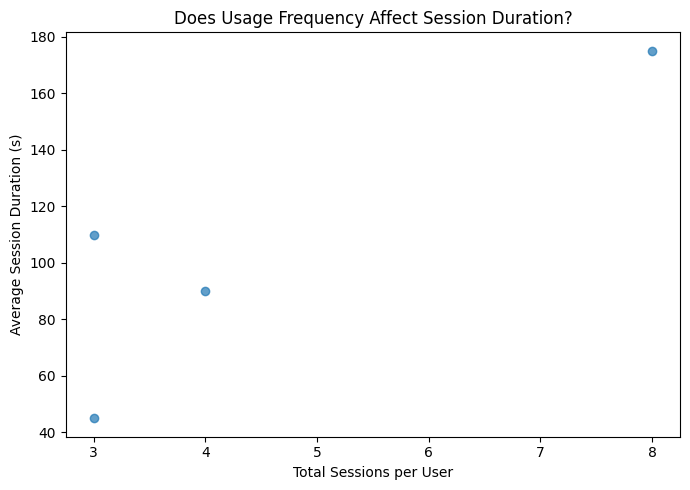

In [2]:
df = pd.DataFrame({
    'user_id': [1,2,3,4],
    'session_count_auto': [5,2,0,1],
    'session_count_manual': [3,1,4,2],
    'mean_duration_auto': [200, 50, 0, 120],
    'mean_duration_manual': [150, 40, 180, 100]
})
plot_sessions_vs_avg_duration(df)


### plot_session_duration_distribution(events)

Histogram of durations by type. Provide `events` DataFrame with columns `type` and `session_duration`.

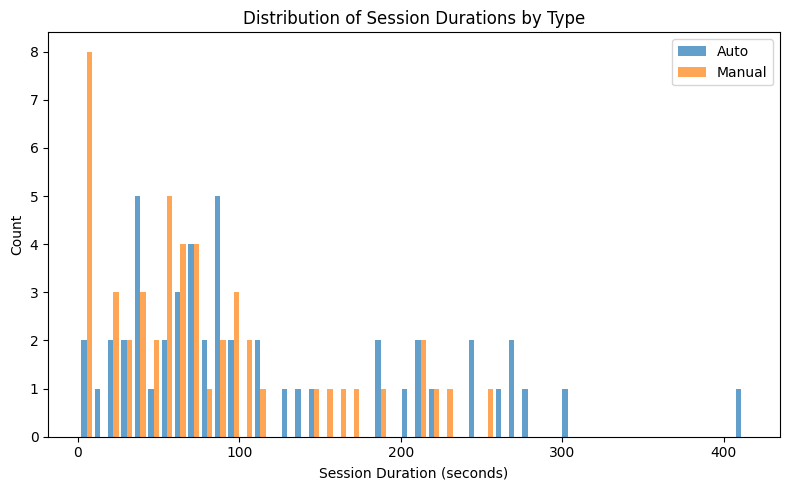

In [3]:
events = pd.DataFrame({
    'type': ['auto']*50 + ['manual']*50,
    'session_duration': np.concatenate([np.random.exponential(scale=120, size=50), np.random.exponential(scale=80, size=50)])
})
plot_session_duration_distribution(events)


### plot_session_count_summary(summary)

Bar chart: expects the `summary` DataFrame produced by `duration_summary()` in the main notebook.

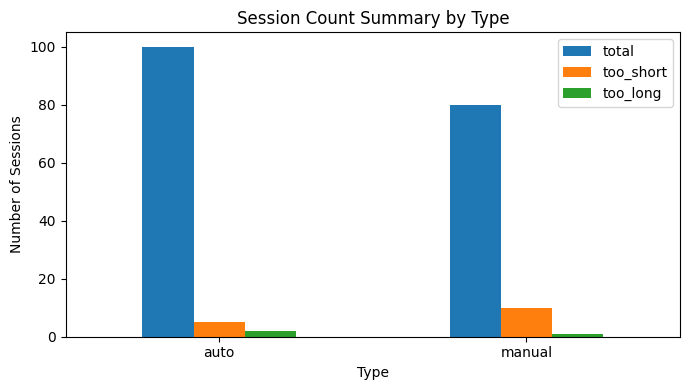

In [4]:
summary = pd.DataFrame({'total': [100, 80], 'too_short': [5,10], 'too_long':[2,1]}, index=['auto', 'manual'])
plot_session_count_summary(summary)


### plot_faulty_data(processor, labels=None)

Displays processor.faulty_data as a bar chart. `labels` can rename the index.


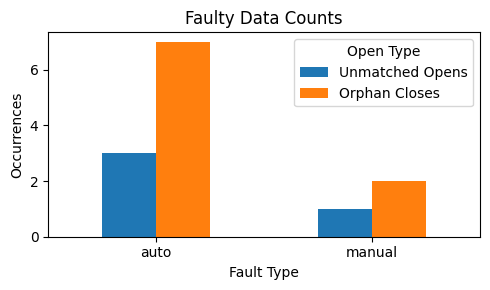

In [5]:
# Simulate a processor.faulty_data DataFrame to demonstrate the plot
import pandas as pd
class DummyProc:
    pass
p = DummyProc()
p.faulty_data = pd.DataFrame({'auto':[3,7], 'manual':[1,2]})
plot_faulty_data(p, labels=['Unmatched Opens','Orphan Closes'])


### plot_avg_session_duration_per_user(user_stats)

Line chart of mean duration per user; requires `user_stats` with `user_id`, `mean_duration_auto`, `mean_duration_manual`.

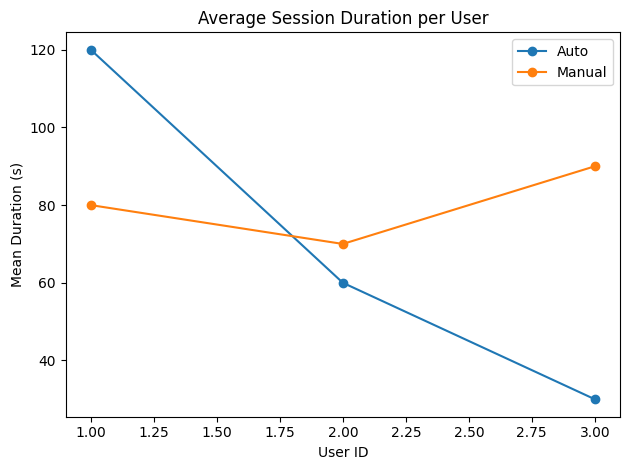

In [6]:
user_stats = pd.DataFrame({'user_id':[1,2,3], 'mean_duration_auto':[120, 60, 30], 'mean_duration_manual':[80, 70, 90]})
plot_avg_session_duration_per_user(user_stats)


### plot_session_count_per_user(user_stats)

Line chart showing counts per user.

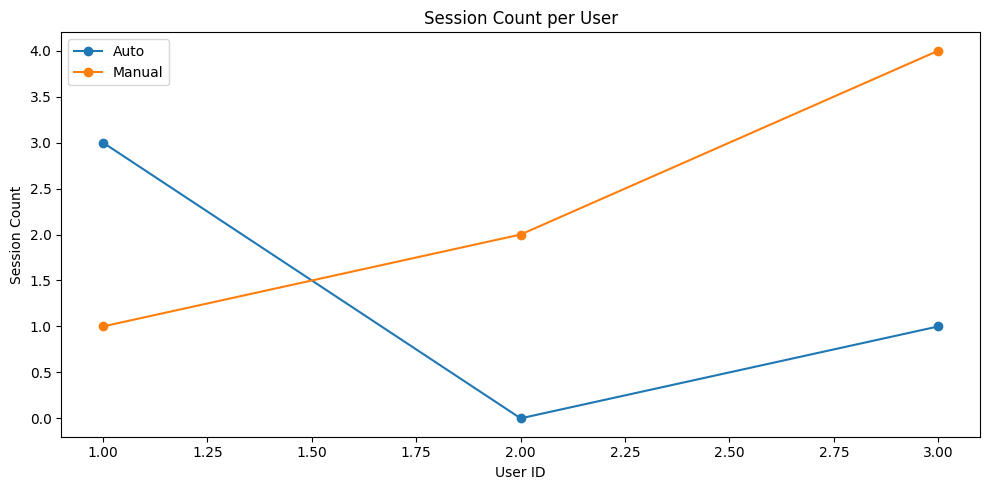

In [7]:
user_stats = pd.DataFrame({'user_id':[1,2,3], 'session_count_auto':[3,0,1], 'session_count_manual':[1,2,4]})
plot_session_count_per_user(user_stats)


### plot_mean_sd_duration(mean, std_dev, cohens_d)

Bar chart with error bars. Provide `mean` and `std_dev` as Series indexed by type, and Cohen's d value.

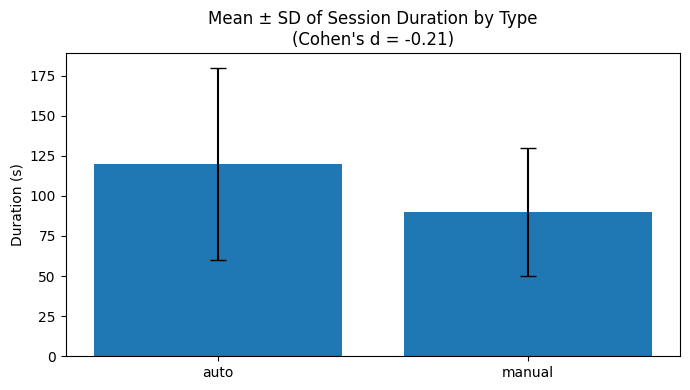

In [8]:
mean = pd.Series({'auto':120, 'manual':90})
std = pd.Series({'auto':60, 'manual':40})
plot_mean_sd_duration(mean, std, cohens_d= -0.21)


### plot_session_duration_boxplot(events)

Boxplot of durations per type.

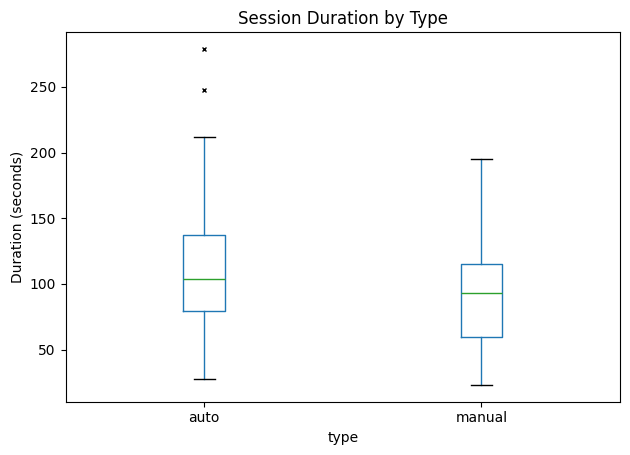

In [9]:
events = pd.DataFrame({
    'type': ['auto']*40 + ['manual']*40,
    'session_duration': np.concatenate([np.random.normal(120, 60, 40), np.random.normal(90, 40, 40)])
})
plot_session_duration_boxplot(events)
